# Telecom Customer Churn Prediction

## Project Overview
This project predicts whether a telecom customer
is likely to leave the company using Machine Learning.

## Dataset
IBM Telco Customer Churn Dataset

- Total Customers: 7043
- Total Features: 21
- Target Variable: Churn

In [1]:

# Import necessary libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset

df = pd.read_csv("dataset/telco_customer_churn.csv")

# Display first 5 rows

df.head()



,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:

# Check dataset dimensions

print("Dataset Shape:", df.shape)

# Check column names

print("\nColumn Names:")
print(df.columns.tolist())

# Check data types and non-null values

print("\nDataset Information:")
df.info()

# Check missing values

print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records

print("\nDuplicate Records:", df.duplicated().sum())


Dataset Shape: (7043, 21)

Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    


In [3]:

print("Churn Count:")
print(df["Churn"].value_counts())

print("\nChurn Percentage:")
print(df["Churn"].value_counts(normalize=True) * 100)


Churn Count:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [4]:

# Convert TotalCharges into numeric format

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Check missing values again

print("Missing Values:")
print(df.isnull().sum())

# Check TotalCharges datatype

print("\nTotalCharges Data Type:")
print(df["TotalCharges"].dtype)


Missing Values:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

TotalCharges Data Type:
float64


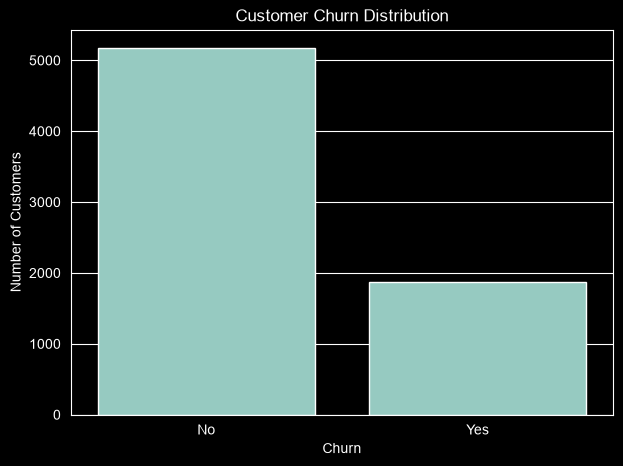

In [5]:

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()


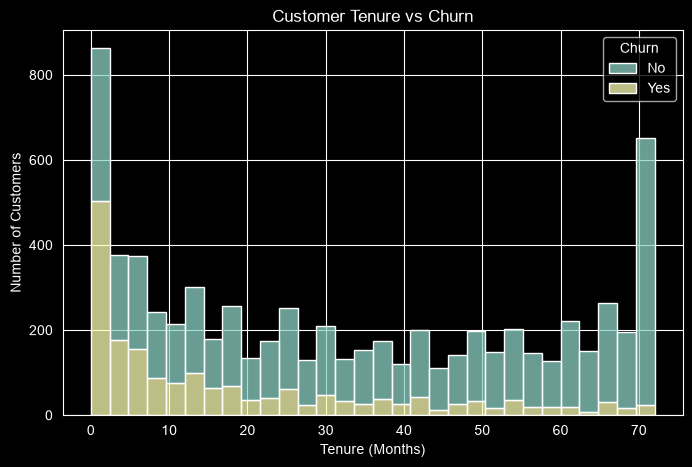

In [6]:

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=30,
    multiple="stack"
)

plt.title("Customer Tenure vs Churn")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.show()


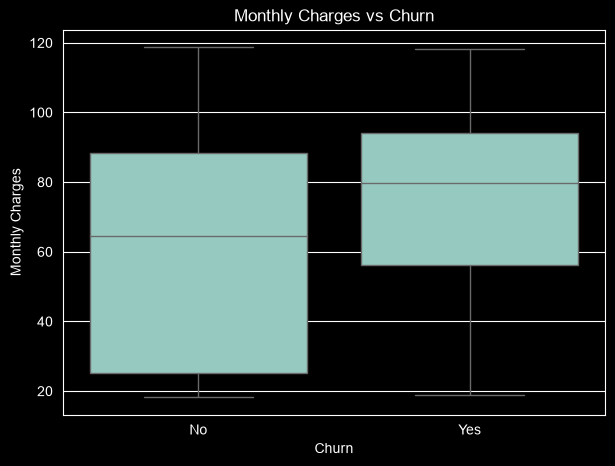

In [7]:

plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()


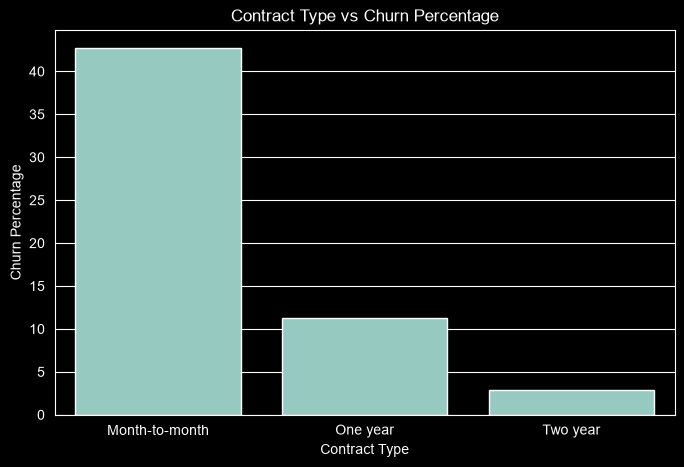

In [8]:

contract_churn = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="ChurnPercentage")
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=contract_churn,
    x="Contract",
    y="ChurnPercentage"
)

plt.title("Contract Type vs Churn Percentage")
plt.xlabel("Contract Type")
plt.ylabel("Churn Percentage")

plt.show()


In [9]:

# Check records where TotalCharges is missing

df[df["TotalCharges"].isnull()][
    ["tenure", "MonthlyCharges", "TotalCharges"]
]


,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


In [11]:

# Fill missing TotalCharges with 0

df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Verify missing values

print("Missing TotalCharges:",
      df["TotalCharges"].isnull().sum())

print("TotalCharges Data Type:",
      df["TotalCharges"].dtype)


Missing TotalCharges: 0
TotalCharges Data Type: float64


In [14]:

# Remove customerID column

df = df.drop("customerID", axis=1)

# Separate input features and target variable

X = df.drop("Churn", axis=1)
y = df["Churn"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Values:")
print(y.value_counts())


Features Shape: (7043, 19)
Target Shape: (7043,)

Target Values:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [18]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (5634, 19)
Testing Data: (1409, 19)


In [20]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Identify numerical and categorical columns

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "str"]
).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)


Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [21]:

# Numerical Data Preprocessing

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical Data Preprocessing

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine Both Pipelines

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing Pipeline Created Successfully!")


Preprocessing Pipeline Created Successfully!


In [22]:

# Apply preprocessing to training data

X_train_processed = preprocessor.fit_transform(X_train)

# Apply preprocessing to testing data

X_test_processed = preprocessor.transform(X_test)

print("Training Data Shape:", X_train_processed.shape)
print("Testing Data Shape:", X_test_processed.shape)


Training Data Shape: (5634, 45)
Testing Data Shape: (1409, 45)


In [23]:

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Create Models

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42)
}

print("All 3 Models Created Successfully!")


All 3 Models Created Successfully!


In [24]:

# Train all three models

for name, model in models.items():
    model.fit(X_train_processed, y_train)
    print(name, "Training Completed Successfully!")



Logistic Regression Training Completed Successfully!
Decision Tree Training Completed Successfully!
Random Forest Training Completed Successfully!


In [26]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Evaluate all models

for name, model in models.items():

    y_pred = model.predict(X_test_processed)

    print("\n", name)
    print("----------------------------")

    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred, pos_label="Yes"))
    print("Recall:", recall_score(y_test, y_pred, pos_label="Yes"))
    print("F1 Score:", f1_score(y_test, y_pred, pos_label="Yes"))



 Logistic Regression
----------------------------
Accuracy: 0.8055358410220014
Precision: 0.6572327044025157
Recall: 0.5588235294117647
F1 Score: 0.6040462427745664

 Decision Tree
----------------------------
Accuracy: 0.7189496096522356
Precision: 0.4713541666666667
Recall: 0.4839572192513369
F1 Score: 0.47757255936675463

 Random Forest
----------------------------
Accuracy: 0.7792760823278921
Precision: 0.6082474226804123
Recall: 0.4732620320855615
F1 Score: 0.5323308270676692


In [27]:

from sklearn.metrics import f1_score

for name, model in models.items():
    y_pred = model.predict(X_test_processed)

    print(name, "F1 Score:",
          f1_score(y_test, y_pred, pos_label="Yes"))


Logistic Regression F1 Score: 0.6040462427745664
Decision Tree F1 Score: 0.47757255936675463
Random Forest F1 Score: 0.5323308270676692


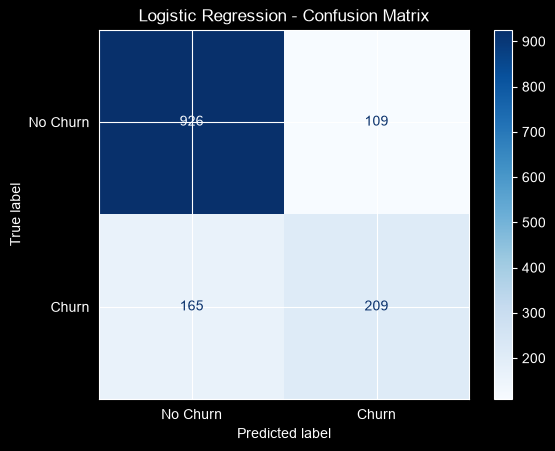

In [28]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Predict using Logistic Regression

best_model = models["Logistic Regression"]
y_pred = best_model.predict(X_test_processed)

# Create Confusion Matrix

cm = confusion_matrix(y_test, y_pred, labels=["No", "Yes"])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot(cmap="Blues")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()


In [29]:

from sklearn.metrics import classification_report

print("Classification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    target_names=["No Churn", "Churn"]
))


Classification Report:

              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [30]:

import joblib

# Save trained model and preprocessor

joblib.dump(best_model, "churn_model.pkl")
joblib.dump(preprocessor, "preprocessor.pkl")

print("Model Saved Successfully!")


Model Saved Successfully!
